In [ ]:
!pip install vnstock

Đang thu thập dữ liệu cho mã FPT...


2025-03-19 08:53:53 - vnstock.common.data.data_explorer - WARNING - Thông tin niêm yết & giao dịch sẽ được truy xuất từ TCBS


Số mẫu dữ liệu: 3746
Đang tính toán các chỉ báo kỹ thuật...
Số mẫu dữ liệu sau khi tính chỉ báo kỹ thuật: 3723
Đang áp dụng kỹ thuật mở rộng tính năng...
Số tính năng sau khi mở rộng: 30
Số mẫu dữ liệu sau khi mở rộng: 3703
Đang áp dụng kỹ thuật loại bỏ tính năng đệ quy...
Phát hiện chỉ mục kiểu datetime, đang reset chỉ mục...
Phát hiện và loại bỏ các cột datetime: time
Kiểm tra và xử lý các giá trị NaN hoặc infinity...
Phát hiện 263 giá trị NaN, đang thay thế...
Các tính năng được chọn sau RFE: BIAS20, CCI24, MTM10, ROC10, WNR9, SlowK9, SMA10_scaled, ROC10_scaled, WNR9_scaled, SlowK9_scaled, SMA10_pct, MTM10_pct, ROC10_pct, RSI14_pct, WNR9_pct
Số tính năng sau RFE: 15
Đang áp dụng kỹ thuật phân tích thành phần chính...
Tổng phương sai giải thích được với 6 thành phần: 99.27%
Số thành phần sau PCA: 6
Đang chuẩn bị dữ liệu cho XGBoost với cửa sổ thời gian 60 ngày...
Shape của X_train: (2914, 72)
Shape của X_test: (729, 72)
Đang xây dựng mô hình XGBoost...
Đang huấn luyện mô hình XGBoost

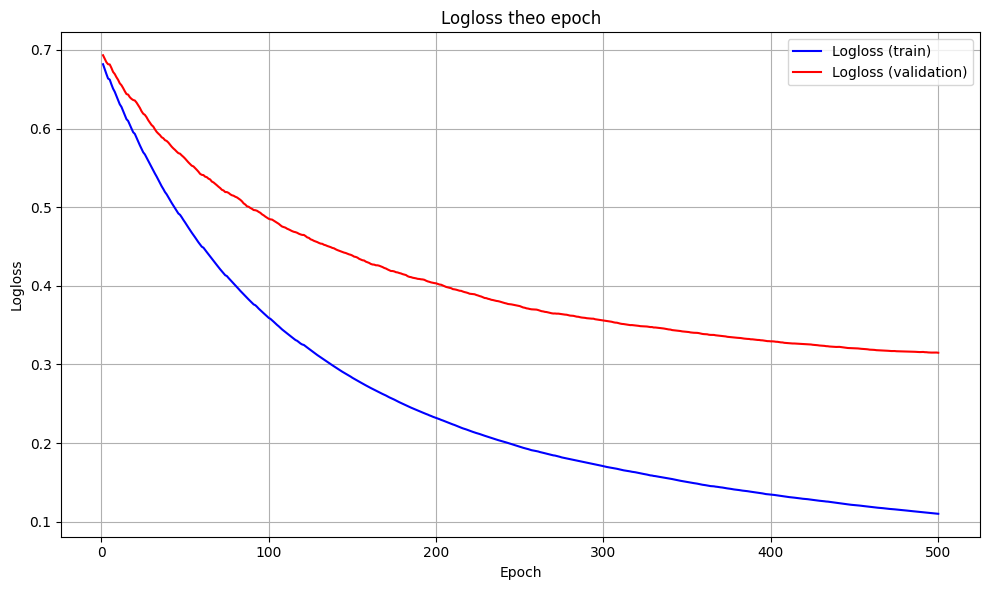

Đang đánh giá hiệu suất mô hình...
Độ chính xác (Accuracy): 85.19%
Độ chính xác (Precision): 82.65%
Độ bao phủ (Recall): 89.01%
F1-Score: 85.71%
ROC-AUC: 94.73%


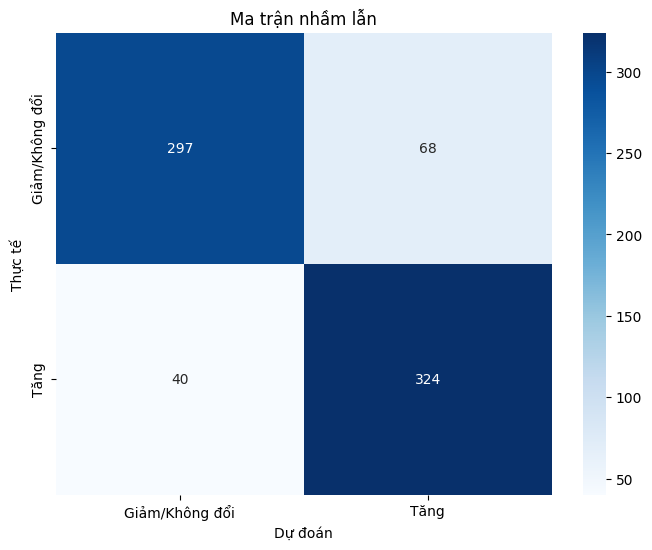

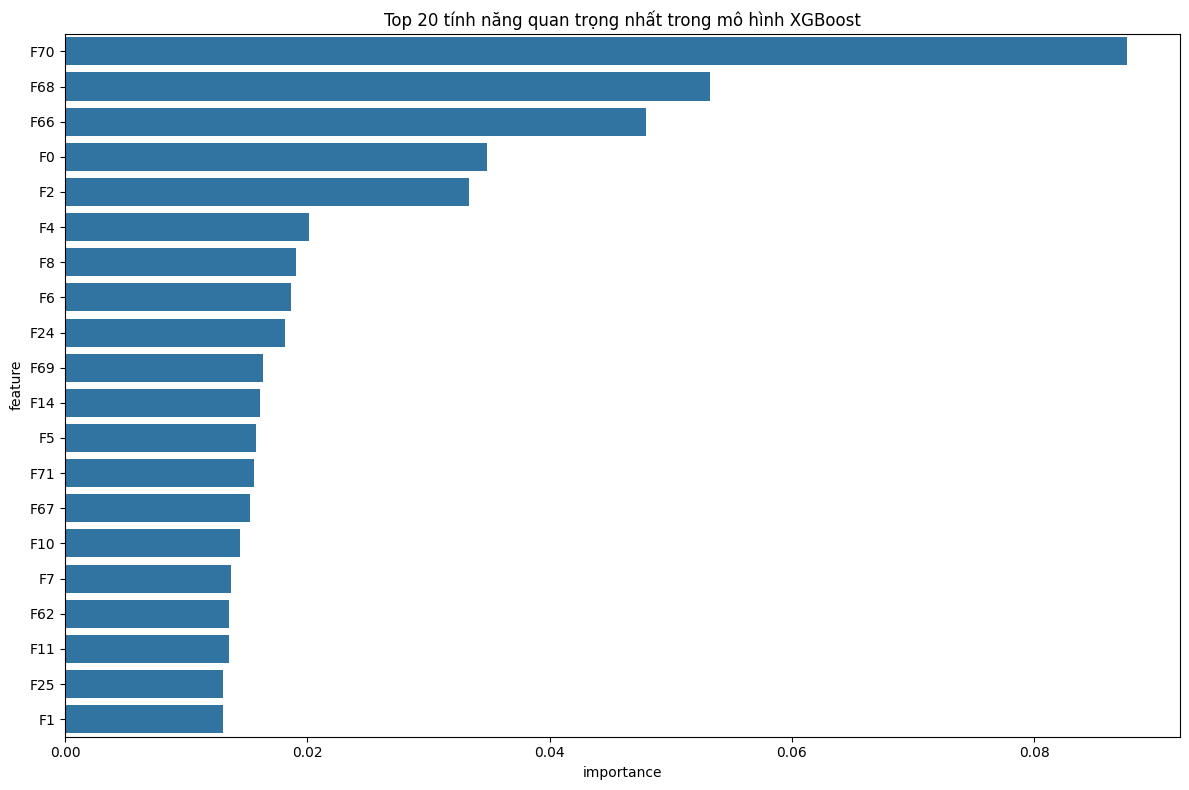


===== KẾT QUẢ DỰ ĐOÁN =====
Mã cổ phiếu: FPT
Xác suất tăng giá ngày tiếp theo: 24.34%
Dự đoán xu hướng: Giảm giá/Không đổi
Đã lưu mô hình tại: xgboost_model_FPT_20250319.json


In [ ]:
# Import các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import RFE
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb  # Thêm thư viện XGBoost
import datetime
import warnings

# Bỏ qua các cảnh báo
warnings.filterwarnings('ignore')

# Thiết lập seed cho khả năng tái tạo
np.random.seed(42)

# 1. Thu thập dữ liệu
def get_stock_data(symbol):
    """Lấy dữ liệu cổ phiếu từ API"""

    from vnstock import Vnstock
    vnstock_api = Vnstock()

    # Định nghĩa khoảng thời gian
    start_date = "2010-03-18"
    end_date = pd.Timestamp.today().strftime('%Y-%m-%d')

    print(f"Đang thu thập dữ liệu cho mã {symbol}...")
    stock = vnstock_api.stock(symbol=symbol, source='VCI')
    data = stock.quote.history(start=start_date, end=end_date)

    # Đảm bảo cột ngày tháng là index
    if 'time' in data.columns:
        data.set_index('time', inplace=True)

    # Đổi tên cột phù hợp với nghiên cứu
    data.rename(columns={'open': 'Open', 'high': 'High', 'low': 'Low',
                        'close': 'Close', 'volume': 'Volume'}, inplace=True)

    # Tính thêm Amount (Giá trị giao dịch)
    data['Amount'] = data['Volume'] * data['Close']

    # Gán nhãn: 1 nếu giá đóng cửa tăng so với ngày hôm trước, 0 nếu giảm hoặc không đổi
    data['Target'] = (data['Close'] > data['Close'].shift(1)).astype(int)

    # Tính giá trần và giá sàn (theo quy định của sàn VN)
    data['Ceiling_Price'] = data['Close'].shift(1) * 1.07  # Biên độ dao động 7%
    data['Floor_Price'] = data['Close'].shift(1) * 0.93

    return data

# 2. Tính toán các chỉ báo kỹ thuật (giữ nguyên)
def calculate_technical_indicators(df):
    """Tính toán các chỉ báo kỹ thuật như trong nghiên cứu"""
    print("Đang tính toán các chỉ báo kỹ thuật...")
    df_tech = df.copy()

    # Simple Moving Average 10 days
    df_tech['SMA10'] = df_tech['Close'].rolling(window=10).mean()

    # BIAS20 - Chỉ số lệch
    df_tech['BIAS20'] = (df_tech['Close'] - df_tech['Close'].rolling(window=20).mean()) / df_tech['Close'].rolling(window=20).mean() * 100

    # CCI24 - Commodity Channel Index
    typical_price = (df_tech['High'] + df_tech['Low'] + df_tech['Close']) / 3
    mean_dev = typical_price.rolling(window=24).std()
    df_tech['CCI24'] = (typical_price - typical_price.rolling(window=24).mean()) / (0.015 * mean_dev)

    # MTM10 - Momentum
    df_tech['MTM10'] = df_tech['Close'] - df_tech['Close'].shift(10)

    # ROC10 - Rate of Change
    df_tech['ROC10'] = (df_tech['Close'] - df_tech['Close'].shift(10)) / df_tech['Close'].shift(10) * 100

    # RSI14 - Relative Strength Index
    delta = df_tech['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df_tech['RSI14'] = 100 - (100 / (1 + rs))

    # WNR9 - Williams %R
    highest_high = df_tech['High'].rolling(window=9).max()
    lowest_low = df_tech['Low'].rolling(window=9).min()
    df_tech['WNR9'] = (highest_high - df_tech['Close']) / (highest_high - lowest_low) * -100

    # Stochastic oscillator (SlowK9 and SlowD3)
    df_tech['SlowK9'] = ((df_tech['Close'] - lowest_low) / (highest_high - lowest_low)) * 100
    df_tech['SlowD3'] = df_tech['SlowK9'].rolling(window=3).mean()

    # Bỏ các giá trị NaN từ việc tính toán rolling windows
    df_tech.dropna(inplace=True)

    return df_tech

# 3. Mở rộng tính năng (Feature Expansion) (giữ nguyên)
def feature_expansion(df):
    """Áp dụng kỹ thuật mở rộng tính năng như trong nghiên cứu"""
    print("Đang áp dụng kỹ thuật mở rộng tính năng...")
    df_expanded = df.copy()

    # Danh sách các tính năng áp dụng phương pháp chia tỷ lệ tối đa - tối thiểu
    min_max_features = ['Volume', 'Amount', 'SMA10', 'ROC10', 'RSI14', 'WNR9', 'SlowK9']

    # Áp dụng MinMaxScaler cho các tính năng được chọn
    scaler = MinMaxScaler(feature_range=(0, 1))
    for feature in min_max_features:
        df_expanded[f'{feature}_scaled'] = scaler.fit_transform(df_expanded[feature].values.reshape(-1, 1))

    # Tính phần trăm dao động cho các tính năng được chọn
    pct_change_features = ['SMA10', 'MTM10', 'ROC10', 'RSI14', 'WNR9']
    for feature in pct_change_features:
        df_expanded[f'{feature}_pct'] = df_expanded[feature].pct_change() * 100

    # Bỏ các hàng có giá trị NaN sau khi tính phần trăm thay đổi
    df_expanded.dropna(inplace=True)

    return df_expanded

# 4. Loại bỏ tính năng đệ quy (Recursive Feature Elimination) (giữ nguyên)
def apply_rfe(df, target_column='Target', n_features_to_select=15):
    """Áp dụng kỹ thuật loại bỏ tính năng đệ quy"""
    print("Đang áp dụng kỹ thuật loại bỏ tính năng đệ quy...")

    # Tạo bản sao của DataFrame để tránh thay đổi dữ liệu gốc
    df_copy = df.copy()

    # Kiểm tra nếu index là kiểu datetime và reset nếu cần
    if isinstance(df_copy.index, pd.DatetimeIndex):
        print("Phát hiện chỉ mục kiểu datetime, đang reset chỉ mục...")
        df_copy = df_copy.reset_index()

    # Xác định và loại bỏ các cột datetime
    datetime_columns = df_copy.select_dtypes(include=['datetime64']).columns
    if len(datetime_columns) > 0:
        print(f"Phát hiện và loại bỏ các cột datetime: {', '.join(datetime_columns)}")
        df_copy = df_copy.drop(columns=datetime_columns)

    # Kiểm tra và xử lý các giá trị NaN hoặc infinity
    print("Kiểm tra và xử lý các giá trị NaN hoặc infinity...")

    # Thay thế giá trị infinity bằng NaN
    df_copy = df_copy.replace([np.inf, -np.inf], np.nan)

    # Đếm số lượng giá trị NaN
    nan_count = df_copy.isna().sum().sum()
    if nan_count > 0:
        print(f"Phát hiện {nan_count} giá trị NaN, đang thay thế...")
        # Thay thế giá trị NaN bằng giá trị mean của cột tương ứng
        df_copy = df_copy.fillna(df_copy.mean())

    # Chuẩn bị dữ liệu
    exclude_columns = ['Target', 'Open', 'High', 'Low', 'Close', 'Ceiling_Price', 'Floor_Price', 'index', 'date', 'Date']
    feature_columns = [col for col in df_copy.columns if col not in exclude_columns]
    X = df_copy[feature_columns]
    y = df_copy[target_column]

    # Kiểm tra phạm vi giá trị để phù hợp với float32
    max_float32 = np.finfo('float32').max
    min_float32 = np.finfo('float32').min

    # Xác định các cột có giá trị vượt ngưỡng float32
    problematic_columns = []
    for col in X.columns:
        if X[col].max() > max_float32 or X[col].min() < min_float32:
            problematic_columns.append(col)

    if problematic_columns:
        print(f"Phát hiện các cột có giá trị vượt ngưỡng float32: {', '.join(problematic_columns)}")
        # Chuẩn hóa các cột có vấn đề
        scaler = MinMaxScaler(feature_range=(-1, 1))
        for col in problematic_columns:
            X[col] = scaler.fit_transform(X[col].values.reshape(-1, 1))

    # Chuyển đổi dữ liệu sang kiểu float64 để tránh vấn đề với float32
    X = X.astype(np.float64)

    # Khởi tạo model cho RFE
    model = GradientBoostingClassifier(random_state=42)

    # Khởi tạo RFE
    selector = RFE(estimator=model, n_features_to_select=n_features_to_select, step=1)

    # Huấn luyện RFE
    selector = selector.fit(X, y)

    # Lấy các tính năng được chọn
    selected_features = X.columns[selector.support_]

    print(f"Các tính năng được chọn sau RFE: {', '.join(selected_features)}")

    # Tạo dữ liệu mới chỉ với các tính năng được chọn
    X_selected = X[selected_features]

    # Tạo DataFrame mới với các tính năng được chọn và cột Target
    df_rfe = pd.DataFrame(X_selected)
    df_rfe['Target'] = y.values

    return df_rfe, selected_features

# 5. Phân tích thành phần chính (Principal Component Analysis) (giữ nguyên)
def apply_pca(df, target_column='Target', n_components=6):
    """Áp dụng kỹ thuật phân tích thành phần chính"""
    print("Đang áp dụng kỹ thuật phân tích thành phần chính...")

    # Tách dữ liệu thành đặc trưng và nhãn
    X = df.drop(columns=[target_column])
    y = df[target_column]

    # Chuẩn hóa dữ liệu
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    # Áp dụng PCA
    pca = PCA(n_components=n_components)
    X_pca = pca.fit_transform(X_scaled)

    # Tạo DataFrame mới với các thành phần chính
    df_pca = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(n_components)])
    df_pca['Target'] = y.values

    # Phương sai giải thích được
    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)

    print(f"Tổng phương sai giải thích được với {n_components} thành phần: {cumulative_variance[-1]:.2%}")

    return df_pca, pca, explained_variance

# 6. Chuẩn bị dữ liệu cho XGBoost với chuỗi thời gian
def prepare_data_for_xgboost(df, target_column='Target', time_steps=60, test_size=0.2):
    """Chuẩn bị dữ liệu cho mô hình XGBoost với chuỗi thời gian"""
    print(f"Đang chuẩn bị dữ liệu cho XGBoost với cửa sổ thời gian {time_steps} ngày...")

    # Tách dữ liệu thành đặc trưng và nhãn
    X = df.drop(columns=[target_column]).values
    y = df[target_column].values

    # Tạo tính năng từ chuỗi thời gian cho XGBoost
    # Sử dụng kỹ thuật tạo lag features để đưa thông tin chuỗi thời gian vào XGBoost
    X_time_features = []
    y_time_features = []

    for i in range(time_steps, len(X)):
        # Tạo features phẳng từ các time step trước đó (các lag)
        # Cách 1: Chỉ lấy điểm cuối chuỗi
        features = []

        # Thêm lags trực tiếp (vd: 1 ngày trước, 2 ngày trước,...)
        for lag in [1, 2, 3, 5, 10, 20, 30]:
            if i - lag >= 0:
                features.extend(X[i - lag])

        # Thêm tính năng thống kê từ cửa sổ thời gian
        window = X[i-time_steps:i]

        # Giá trị trung bình
        mean_values = np.mean(window, axis=0)
        features.extend(mean_values)

        # Độ lệch chuẩn
        std_values = np.std(window, axis=0)
        features.extend(std_values)

        # Min-max
        min_values = np.min(window, axis=0)
        max_values = np.max(window, axis=0)
        features.extend(min_values)
        features.extend(max_values)

        # Thêm giá trị hiện tại
        features.extend(X[i])

        X_time_features.append(features)
        y_time_features.append(y[i])

    # Chuyển về mảng numpy
    X_time_features, y_time_features = np.array(X_time_features), np.array(y_time_features)

    # Chia dữ liệu thành tập huấn luyện và tập kiểm tra
    train_size = int(len(X_time_features) * (1 - test_size))
    X_train, X_test = X_time_features[:train_size], X_time_features[train_size:]
    y_train, y_test = y_time_features[:train_size], y_time_features[train_size:]

    print(f"Shape của X_train: {X_train.shape}")
    print(f"Shape của X_test: {X_test.shape}")

    return X_train, X_test, y_train, y_test

# 7. Xây dựng mô hình XGBoost cho dự đoán chuỗi thời gian
def build_xgboost_model(params=None):
    """Xây dựng mô hình XGBoost cho dự đoán chuỗi thời gian"""
    print("Đang xây dựng mô hình XGBoost...")

    # Thiết lập tham số mặc định nếu không được cung cấp
    if params is None:
        params = {
            'n_estimators': 300,
            'max_depth': 5,
            'learning_rate': 0.05,
            'subsample': 0.8,
            'colsample_bytree': 0.8,
            'objective': 'binary:logistic',
            'eval_metric': 'logloss',
            'random_state': 42
        }

    # Tạo mô hình XGBoost
    model = xgb.XGBClassifier(**params)

    return model

# 8. Huấn luyện mô hình XGBoost
def train_xgboost_model(model, X_train, y_train, X_test=None, y_test=None):
    """Huấn luyện mô hình XGBoost"""
    print("Đang huấn luyện mô hình XGBoost...")

    # Tạo tập dữ liệu đánh giá nếu có X_test và y_test
    eval_set = None
    if X_test is not None and y_test is not None:
        eval_set = [(X_train, y_train), (X_test, y_test)]

    # Huấn luyện mô hình
    model.fit(X_train, y_train,
              eval_set=eval_set,
              verbose=True)

    # Lấy lịch sử huấn luyện nếu có
    evals_result = model.evals_result() if hasattr(model, 'evals_result') else None

    return model, evals_result

# 9. Đánh giá hiệu suất mô hình
def evaluate_model(model, X_test, y_test):
    """Đánh giá hiệu suất của mô hình"""
    print("Đang đánh giá hiệu suất mô hình...")

    # Dự đoán trên tập kiểm tra
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_prob > 0.5).astype(int)

    # Tính các chỉ số đánh giá
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_prob)

    # Tạo ma trận nhầm lẫn
    cm = confusion_matrix(y_test, y_pred)

    # In các chỉ số đánh giá
    print(f"Độ chính xác (Accuracy): {acc:.2%}")
    print(f"Độ chính xác (Precision): {prec:.2%}")
    print(f"Độ bao phủ (Recall): {rec:.2%}")
    print(f"F1-Score: {f1:.2%}")
    print(f"ROC-AUC: {roc_auc:.2%}")

    # Hiển thị ma trận nhầm lẫn
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Giảm/Không đổi', 'Tăng'],
                yticklabels=['Giảm/Không đổi', 'Tăng'])
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.title('Ma trận nhầm lẫn')
    plt.show()

    # Hiển thị tầm quan trọng của tính năng
    plot_feature_importance(model)

    metrics = {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1,
        'roc_auc': roc_auc
    }

    return metrics

# 10. Hiển thị tầm quan trọng của tính năng
def plot_feature_importance(model, top_n=20):
    """Hiển thị tầm quan trọng của tính năng trong mô hình XGBoost"""

    # Lấy độ quan trọng của tính năng
    importance = model.feature_importances_

    # Tạo DataFrame để dễ dàng trực quan hóa
    feature_names = [f'F{i}' for i in range(len(importance))]
    feature_importance = pd.DataFrame(
        {'feature': feature_names, 'importance': importance}
    )

    # Sắp xếp theo độ quan trọng giảm dần
    feature_importance = feature_importance.sort_values('importance', ascending=False)

    # Giới hạn số lượng tính năng hiển thị
    if len(feature_importance) > top_n:
        feature_importance = feature_importance.head(top_n)

    # Vẽ biểu đồ
    plt.figure(figsize=(12, 8))
    sns.barplot(x='importance', y='feature', data=feature_importance)
    plt.title(f'Top {top_n} tính năng quan trọng nhất trong mô hình XGBoost')
    plt.tight_layout()
    plt.show()

# 11. Dự đoán xu hướng giá cổ phiếu ngày tiếp theo
def predict_next_day(model, last_data):
    """Dự đoán xu hướng giá cổ phiếu ngày tiếp theo"""

    # Dự đoán xác suất tăng giá
    prediction_prob = model.predict_proba([last_data])[0, 1]

    # Chuyển đổi xác suất thành nhãn dự đoán (0: giảm/không đổi, 1: tăng)
    prediction_class = 1 if prediction_prob > 0.5 else 0

    return prediction_prob, prediction_class

# 12. Hiển thị kết quả huấn luyện
def plot_training_history(evals_result):
    """Hiển thị lịch sử huấn luyện của mô hình XGBoost"""

    if evals_result is None:
        print("Không có lịch sử huấn luyện để hiển thị.")
        return

    # Trích xuất metric từ lịch sử huấn luyện
    train_logloss = evals_result['validation_0']['logloss']
    val_logloss = evals_result['validation_1']['logloss']

    # Tạo trục thời gian
    epochs = range(1, len(train_logloss) + 1)

    # Vẽ đồ thị logloss
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, train_logloss, 'b-', label='Logloss (train)')
    plt.plot(epochs, val_logloss, 'r-', label='Logloss (validation)')
    plt.title('Logloss theo epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Logloss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# 13. Hàm chính
def main():
    """Hàm chính thực hiện toàn bộ quy trình"""

    # Thiết lập thông số
    symbol = 'FPT'  # Mã cổ phiếu
    time_steps = 60            # Cửa sổ thời gian (60 ngày giao dịch)
    test_size = 0.2            # Tỷ lệ dữ liệu kiểm tra
    n_features_rfe = 15        # Số tính năng chọn trong RFE
    n_components_pca = 6       # Số thành phần chính trong PCA

    # Thiết lập tham số cho XGBoost
    xgb_params = {
        'n_estimators': 500,
        'max_depth': 6,
        'learning_rate': 0.01,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'random_state': 42
    }

    # 1. Thu thập dữ liệu
    stock_data = get_stock_data(symbol)
    print(f"Số mẫu dữ liệu: {stock_data.shape[0]}")

    # 2. Tính toán chỉ báo kỹ thuật
    stock_data_tech = calculate_technical_indicators(stock_data)
    print(f"Số mẫu dữ liệu sau khi tính chỉ báo kỹ thuật: {stock_data_tech.shape[0]}")

    # 3. Mở rộng tính năng
    stock_data_expanded = feature_expansion(stock_data_tech)
    print(f"Số tính năng sau khi mở rộng: {stock_data_expanded.shape[1]}")
    print(f"Số mẫu dữ liệu sau khi mở rộng: {stock_data_expanded.shape[0]}")

    # 4. Áp dụng RFE
    stock_data_rfe, rfe_features = apply_rfe(stock_data_expanded, n_features_to_select=n_features_rfe)
    print(f"Số tính năng sau RFE: {stock_data_rfe.shape[1] - 1}")  # Trừ 1 để loại bỏ cột Target

    # 5. Áp dụng PCA
    stock_data_pca, pca_model, explained_variance = apply_pca(
        stock_data_rfe, n_components=n_components_pca)
    print(f"Số thành phần sau PCA: {stock_data_pca.shape[1] - 1}")  # Trừ 1 để loại bỏ cột Target

    # 6. Chuẩn bị dữ liệu cho XGBoost
    X_train, X_test, y_train, y_test = prepare_data_for_xgboost(
        stock_data_pca, time_steps=time_steps, test_size=test_size)

    # 7. Xây dựng mô hình XGBoost
    xgb_model = build_xgboost_model(params=xgb_params)

    # 8. Huấn luyện mô hình
    trained_model, evals_result = train_xgboost_model(
        xgb_model, X_train, y_train, X_test, y_test)

    # Hiển thị lịch sử huấn luyện
    plot_training_history(evals_result)

    # 9. Đánh giá mô hình
    metrics = evaluate_model(trained_model, X_test, y_test)

    # 10. Dự đoán xu hướng ngày tiếp theo
    last_data = X_test[-1]  # Lấy dữ liệu của ngày cuối cùng trong tập kiểm tra
    prob, prediction = predict_next_day(trained_model, last_data)

    print("\n===== KẾT QUẢ DỰ ĐOÁN =====")
    print(f"Mã cổ phiếu: {symbol}")
    print(f"Xác suất tăng giá ngày tiếp theo: {prob:.2%}")
    print(f"Dự đoán xu hướng: {'Tăng giá' if prediction == 1 else 'Giảm giá/Không đổi'}")

    # Lưu mô hình
    save_path = f"xgboost_model_{symbol}_{datetime.datetime.now().strftime('%Y%m%d')}.json"
    trained_model.save_model(save_path)
    print(f"Đã lưu mô hình tại: {save_path}")

# Chạy chương trình chính
if __name__ == "__main__":
    main()